# Project 2
## Data 620
### Jane Song

## Introduction 

For this assignment, the MOOC (Massive Open Online Course) user action data will be utilized to analyze student activity connections (https://snap.stanford.edu/data/act-mooc.html). The dataset variables are listed below:

- ACTIONID: a unique id for each action
- USERID: a unique id for each user
- TARGETID: a unique id for each target activity
- TIMESTAMP: timestamp for the action in seconds from the beginning

The 2 variables I will focus on are USERID and TARGETID as they correlate to students and courses and explore the relationship between these groups. We can also see which students and activities remain connected when the network is limited to stronger ties when the size of the network is reduced. 

## Load Data 

In [81]:
import urllib.request
import pandas as pd
import networkx as nx

In [94]:
url = "https://raw.githubusercontent.com/j-song-npc/Data-620/refs/heads/main/Project%202/mooc_actions.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["ACTIONID", "USERID", "TARGETID", "TIMESTAMP"]
)

print(df.shape)
print(df.head())


(411750, 4)
   ACTIONID  USERID  TARGETID  TIMESTAMP
0  ACTIONID  USERID  TARGETID  TIMESTAMP
1         0       0         0      0.000
2         1       0         1      6.000
3         2       0         2     41.000
4         3       0         1     49.000


C:\Users\janej\AppData\Local\Temp\ipykernel_2288\1831730374.py:3: DtypeWarning: Columns (0,1,2,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


## Exploratory data analysis 

In [83]:

# Count interactions for each student and activity match
edges = (
    df.groupby(["USERID", "TARGETID"])
    .size()
    .reset_index(name="weight"))

# Build a weighted bipartite network graph
G = nx.Graph()

for row in edges.itertuples(index=False):
    G.add_edge(
        f"U{row.USERID}",
        f"T{row.TARGETID}",
        weight=row.weight )



In [84]:
print(list(G.nodes())[:10])
print(list(df.columns))
print(df.head())

['U0', 'T12', 'T67', 'T69', 'U1', 'T7', 'U2', 'T20', 'T21', 'T23']
['ACTIONID', 'USERID', 'TARGETID', 'TIMESTAMP']
   ACTIONID  USERID  TARGETID  TIMESTAMP
0  ACTIONID  USERID  TARGETID  TIMESTAMP
1         0       0         0      0.000
2         1       0         1      6.000
3         2       0         2     41.000
4         3       0         1     49.000


In [85]:
students = [n for n in G.nodes() if n.startswith("U")]
activities = [n for n in G.nodes() if n.startswith("T")]

print("Students:", len(students))
print("Activities:", len(activities))
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Students: 7048
Activities: 98
Nodes: 7146
Edges: 178444


In [86]:
# Check if edge weights are included
print(list(G.edges(data=True))[:5])

[('U0', 'T12', {'weight': 3}), ('U0', 'T67', {'weight': 1}), ('U0', 'T69', {'weight': 1}), ('U0', 'T0', {'weight': 2}), ('U0', 'T1', {'weight': 4})]


We can see that there are 7048 students and 98 activities equating to 7146 different nodes and 178,444 edges. Edge weights are a measure of the strength of a connection. In this dataset, the edgeweight would be the frequency that a student interacted with an activity. This information is required to reduce the network using the island method. 

## Network reduction

The island method will be utilized to reduce the network size. Before applying this method, several thresholds will be tested. Thresholds determine the edges of student and activities with at least X number of interactions, reducing the weaker connections. For this analysis, I will be testing 2, 3, 5, 10, 15, and 20. 

In [89]:
thresholds = [2, 3, 5, 10, 15, 20]

for threshold in thresholds:
    H = nx.Graph()

    for u, v, data in G.edges(data=True):
        if data.get("weight", 0) >= threshold:
            H.add_edge(u, v, weight=data["weight"])

    students = sum(n.startswith("U") for n in H.nodes())
    activities = sum(n.startswith("T") for n in H.nodes())
    islands = list(nx.connected_components(H))

    print(
        f"Threshold: {threshold} | "
        f"Students: {students} | "
        f"Activities: {activities} | "
        f"Edges: {H.number_of_edges()} | "
        f"Islands: {len(islands)}")

Threshold: 2 | Students: 6754 | Activities: 97 | Edges: 91563 | Islands: 1
Threshold: 3 | Students: 5737 | Activities: 97 | Edges: 48056 | Islands: 1
Threshold: 5 | Students: 3855 | Activities: 94 | Edges: 15195 | Islands: 1
Threshold: 10 | Students: 1181 | Activities: 75 | Edges: 2018 | Islands: 3
Threshold: 15 | Students: 353 | Activities: 45 | Edges: 474 | Islands: 4
Threshold: 20 | Students: 118 | Activities: 31 | Edges: 142 | Islands: 14


Using a threshold of 2, 3, or 5 creates 1 island while 10 creates 3 islands. The number of activities has not changed significantly in these thresholds as well. The threshold of 2 seems too small with the number of students and edges barely reduced. Thresholds 15 and 20 seems to reduce the number of students in the network too much. Based on these results, I think the threshold of 10 has the best balance in reducing the network and mantaining connections. 

In [90]:
# Use threshold of 10 to evaluate islands
threshold = 10
L = nx.Graph()

for u, v, data in G.edges(data=True):
    if data.get("weight", 0) >= threshold:
        L.add_edge(u, v, weight=data["weight"])

components = sorted(
    nx.connected_components(L),
    key=len,
    reverse=True
)

for i, component in enumerate(components, start=1):
    students = sum(n.startswith("U") for n in component)
    activities = sum(n.startswith("T") for n in component)

    print(
        f"Island {i}: {len(component)} nodes, "
        f"{students} students, {activities} activities"
    )


Island 1: 1252 nodes, 1179 students, 73 activities
Island 2: 2 nodes, 1 students, 1 activities
Island 3: 2 nodes, 1 students, 1 activities


This network at threshold 10 has 1 large island and 2 very small islands. Island 1 is 1,179 students connected to 73 activities and contains nearly all the nodes in the reduced network. Islands 2 and 3 contain 1 student and 1 activity each which suggests an isolated connection. This indicates that the stronger interactions in this network form a strongly interconnected network rather than several isolated groups. Island 1 will be further evaluated next. 

In [91]:
largest_island = L.subgraph(components[0]).copy()

activity_degrees = {
    n: largest_island.degree(n)
    for n in largest_island.nodes()
    if n.startswith("T")}

print("Top 10 activities on the largest island:")
print(sorted(
    activity_degrees.items(),
    key=lambda x: x[1],
    reverse=True
)[:10])

Top 10 activities on the largest island:
[('T21', 524), ('T8', 229), ('T7', 97), ('T9', 86), ('T23', 81), ('T79', 72), ('T5', 65), ('T37', 64), ('T3', 64), ('T12', 61)]


The top 10 activities show that T21 is the most connected in this network with 524 student connected. T8 is second with 229 and the rest have less than 100 student connections. T21 is signficantly more connected to students than the rest of the activities. 

## Network map 

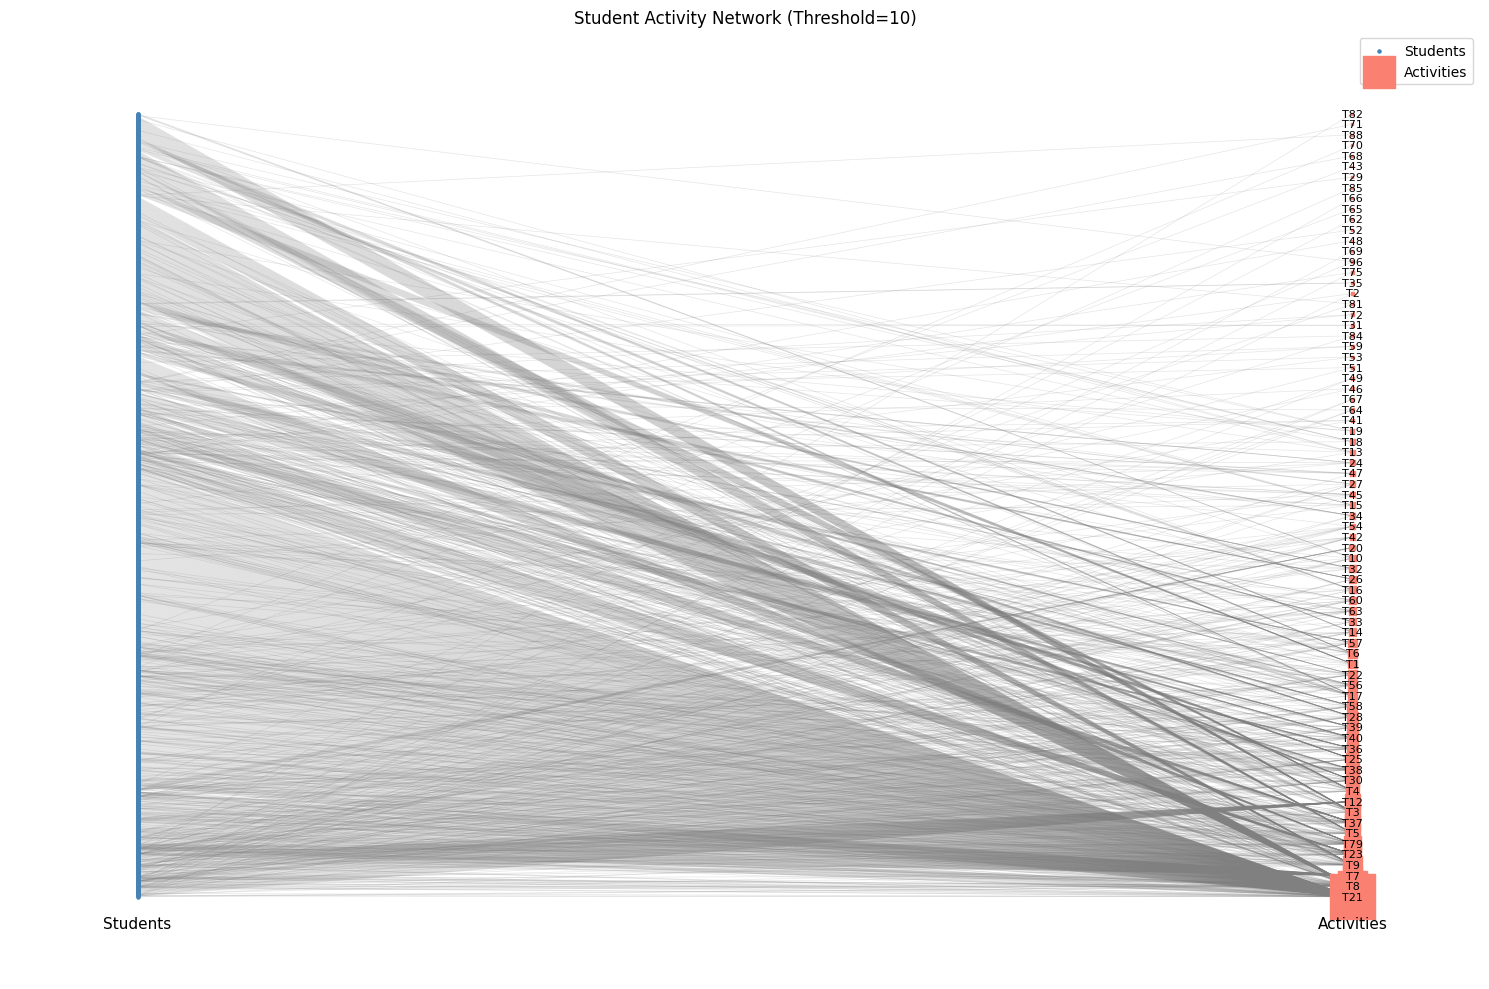

In [93]:

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# Separate the two types of nodes
students = [n for n in L.nodes() if n.startswith("U")]
activities = [n for n in L.nodes() if n.startswith("T")]

pos = {}

for i, node in enumerate(students):
    pos[node] = (0, i / max(len(students) - 1, 1))

# Sort activities by degree 
activities = sorted(activities, key=lambda n: L.degree(n), reverse=True)

for i, node in enumerate(activities):
    pos[node] = (
        1,
        i / max(len(activities) - 1, 1))

# Create the visual
plt.figure(figsize=(15, 10))
nx.draw_networkx_edges(
    L, pos,
    edge_color="gray",
    alpha=0.2,
    width=0.5)

nx.draw_networkx_nodes(
    L, pos,
    nodelist=students,
    node_size=5,
    node_color="steelblue",
    label="Students")

nx.draw_networkx_nodes(
    L, pos,
    nodelist=activities,
    node_size=[L.degree(n) * 2 for n in activities],
    node_color="salmon",
    node_shape="s",
    label="Activities")

# Add labels for activities
nx.draw_networkx_labels(
    L, pos,
    labels={n: n for n in activities},
    font_size=8)

plt.title("Student Activity Network (Threshold=10)")
plt.text(0, -0.04, "Students", ha="center", fontsize=11)
plt.text(1, -0.04, "Activities", ha="center", fontsize=11)
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()


The visualization of this island shows more lines and darker shading, representing more connections, towards activity T21 in particular. It seems that after the top 10 activities, the number of connections become substantially smaller. 

##  Conclusion

This network contains two distinct groups: students and course activities. For students, the reduced network shows which individuals maintained repeated interactions with multiple activities. The student activity network was reduced by applying thresholds to edge weights, retaining only ties with at least a specified number of recorded interactions. As the threshold increased from 2 to 10, the number of edges decreased from 91,563 to 2,018. The network remained connected at thresholds of 2, 3, and 5, but separated into three connected islands at a threshold of 10. 

The reduced network at a threshold of 10 contained one large connected component and two isolated student activity pairs. This suggests that most of the strongest recorded interactions remained connected within a single network, while two pairs were disconnected from the larger group after weaker ties were removed. 

Within the largest island, activity T21 had the highest degree, with 524 student connections, followed by T8 with 229. The next most connected activity, T7, had 97 connections. This indicates that these activities had substantially broader connections among students in the reduced network than the other activities. This suggests that these activities had broader reach among students whose interactions met the selected threshold. 

A limitation of this data is that while there's value to seeing these connections, they reflect course activities, not academic performance. The activity IDs alone do not reveal what the activities represent, and the number of connections should be interpreted as a measure of recorded engagement rather than learning or academic performance. 
